# Reproduction: time averaging of eddy-covariance fluxes — energy-balance closure (Fig. 1 & Table 2)

**Paper:** Karimindla, A. R., Kumari, S., S R, S., Chintala, S., and Kambhammettu, B. V. N. P.: *The role of time averaging of eddy covariance fluxes on water use efficiency dynamics of maize*, Atmos. Meas. Tech., **17**, 5477–5490, 2024. https://doi.org/10.5194/amt-17-5477-2024 (CC-BY 4.0)

**Author code & data:** [Shweta07081992/Effect-of-averaging-period-...](https://github.com/Shweta07081992/Effect-of-averaging-period-of-eddy-covariance-fluxes-on-water-use-efficiency-) pinned at commit `28030cb1d8110d9bf907d1ef031bb6b3470af1cf` (v1.0.0 tree); the same per-figure files are linked via Zenodo doi:10.5281/zenodo.7018282.

**Scope of this notebook (one minimal, runnable analysis):**
1. Reproduce **paper Fig. 1** — diurnal variation of available energy (Rn−G) and turbulent fluxes (H+LE), averaged over the crop cycle — following the authors' own notebook (`SourceFiles for figures and tables/Figure 1/iwm_fig1_final1.ipynb`), for the conventional **30 min** period, plus a clearly labeled extension to all eight averaging periods (1–120 min).
2. Reproduce **paper Table 2** — linear regression of H+LE on Rn−G for each averaging period — from the authors' per-period workbooks (`raw_file/*.xlsx`), and compare the computed slope/intercept/r with the publisher's Table 2 file downloaded inside this notebook.

**Out of scope:** raw 10 Hz processing / EddyPro, growth-stage segmentation, Ogives, and WUE dynamics (Figs. 2–8) — the repository contains no author code or stage keys for those; see the limitations section.

**実行環境 (Japanese):** このノートブックは **CPU のみ** で動作します（GPU 不要）。Colab で「ランタイム → ランタイムのタイプを変更 → CPU」を選択し、**すべてのセルを実行** してください。所要時間は数分、ダウンロード合計は約 6 MB です。

## 1 · Environment setup

This reproduction needs only `pandas`, `numpy`, `matplotlib` (preinstalled on Colab) and `openpyxl` (the Excel reader engine, which Colab does not preinstall). We print versions so the run is reproducible.

**Expected result:** a short report of Python / package versions, with `openpyxl` available for `pd.read_excel`.

(日本語) Colab に未導入の `openpyxl` のみインストールし、バージョンを表示します。

In [ ]:
import sys, subprocess
pkgs = subprocess.run([sys.executable, "-m", "pip", "install", "-q", "openpyxl"],
                      check=True, capture_output=True, text=True)
import numpy as np, pandas as pd, matplotlib, openpyxl
print("python  :", sys.version.split()[0])
print("pandas  :", pd.__version__)
print("numpy   :", np.__version__)
print("matplotlib:", matplotlib.__version__)
print("openpyxl:", openpyxl.__version__)

python  : 3.13.18
pandas  : 2.2.3
numpy   : 2.1.3
matplotlib: 3.10.0
openpyxl: 3.1.5


## 2 · Download the pinned author data (Colab-only, integrity-checked)

The author repository stores the per-figure Excel workbooks. We download, **inside Colab**, only the 16 files needed here (8 time-of-day averaged outputs ≈ 110 KB + 8 raw per-period flux series ≈ 5.7 MB) from the pinned commit, and verify each file's **git blob SHA-1** (computed as `sha1("blob <size>\\0" + bytes)`) against the repository tree recorded at inspection time. The publisher's Table 2 (`amt-17-5477-2024-t02.xlsx`, CC-BY) is downloaded from the journal article page for later comparison.

**Expected result:** a table listing every file with its expected and verified blob SHA-1 and size; a failed hash raises an error.

(日本語) 論文リポジトリの固定コミットから、この再現に必要な 16 個の xlsx（平均化済み 8 + 生データ 8）と出版社版 Table 2 を Colab 内でダウンロードし、git blob SHA-1 で完全性を検証します。

In [ ]:
import hashlib, urllib.request, urllib.parse, pathlib

REPO = 'Shweta07081992/Effect-of-averaging-period-of-eddy-covariance-fluxes-on-water-use-efficiency-'
COMMIT = '28030cb1d8110d9bf907d1ef031bb6b3470af1cf'
BASE = f"https://raw.githubusercontent.com/{REPO}/{COMMIT}/"
T2_URL = 'https://amt.copernicus.org/articles/17/5477/2024/amt-17-5477-2024-t02.xlsx'

DIR_AVG = "SourceFiles for figures and tables/Figure 1/averaged_outputs/"
DIR_RAW = "SourceFiles for figures and tables/Figure 1/raw_file/"

# period_min: (averaged file, avg blob sha1, avg bytes, raw file, raw blob sha1, raw bytes)
FILES = {1: ('1min_fig1_outputs1.xlsx', '21c6b02bda124bf8f180034a45e7e449afa05788', 20322, '1min figure1.xlsx', '450e1699591082f792f235402df8bd01aa812ea7', 1309865), 5: ('5min_fig1_outputs1.xlsx', '7e520968175625498bc680a1529dab366bcfdc91', 18563, '5mins figure1_new.xlsx', '6562d39533e95d2efb58c86f226194e25b40010c', 1118034), 10: ('10min_fig1_outputs1.xlsx', '1665a999055de9fc88f2544bb8db0e4b4789b8ba', 20295, '10min figure1.xlsx', '52b634b6e13df5c9a0ac9fab1304a6803aabf0ad', 1289742), 15: ('15min_fig1_outputs1.xlsx', '17c91742c81a211b438d8a16f99dab4f152f2ff7', 15504, '15min figure1.xlsx', '903199e72bdf6d796eb39f422da3cb7a46e64fab', 865838), 30: ('30min_fig1_outputs1.xlsx', 'af7c7194d20e2fea5243088e30dfe84dd6ee23eb', 10955, '30min figure1.xlsx', '9646cc4c37a59d0e189d1446598fb46350da7992', 439611), 45: ('45min_fig1_outputs1.xlsx', 'eca5cfe0bd6daa8b92fbc2ff6a375a05fb2dc705', 9071, '45min figure1.xlsx', '7bc7a3f00c9af00782760d609334d1f4d74c3bb0', 293912), 60: ('60min_fig1_outputs1.xlsx', 'b445a7023ecd1187d2e30daf91b91c103b311b69', 8267, '60min figure1.xlsx', '4e4a8151921aa1fda4d9d38cf05b0cf692754b5b', 224087), 120: ('120min_fig1_outputs1.xlsx', '5b9c749c00ad107a4929770c1a176e89425c667d', 7699, '120min figure1.xlsx', '2b437d67d5df37a22b36beb71c5fb7306301679d', 108900)}

def fetch(url):
    req = urllib.request.Request(url, headers={"User-Agent": "colab-reproduction/1.0"})
    with urllib.request.urlopen(req, timeout=120) as r:
        return r.read()

def check(url, blob_sha, nbytes, dest):
    data = fetch(url)
    assert len(data) == nbytes, f"{url}: size {len(data)} != expected {nbytes}"
    digest = hashlib.sha1(b"blob %d\x00" % len(data) + data).hexdigest()
    assert digest == blob_sha, f"{url}: blob sha1 {digest} != expected {blob_sha}"
    p = pathlib.Path(dest); p.parent.mkdir(parents=True, exist_ok=True)
    p.write_bytes(data)
    return len(data)

rows = []
for T, (af, ash, abytes, rf, rsh, rbytes) in FILES.items():
    n1 = check(BASE + urllib.parse.quote(DIR_AVG + af), ash, abytes, f"data/averaged/{af}")
    n2 = check(BASE + urllib.parse.quote(DIR_RAW + rf), rsh, rbytes, f"data/raw/{T}min.xlsx")
    rows.append({"T": T, "averaged_file": af, "avg_bytes": n1, "raw_bytes": n2})

# Publisher Table 2 has no published checksum; validate by its zip signature and parse below.
req = urllib.request.Request(T2_URL, headers={"User-Agent": "colab-reproduction/1.0"})
t2_bytes = urllib.request.urlopen(req, timeout=120).read()
assert t2_bytes[:2] == b"PK", "publisher Table 2 is not a valid xlsx (zip signature)"
pathlib.Path("data/table2_publisher.xlsx").write_bytes(t2_bytes)

import pandas as pd
print(pd.DataFrame(rows).to_string(index=False))
print("publisher Table 2 xlsx:", len(t2_bytes), "bytes (zip signature OK)")

  T             averaged_file  avg_bytes  raw_bytes
  1   1min_fig1_outputs1.xlsx      20322    1309865
  5   5min_fig1_outputs1.xlsx      18563    1118034
 10  10min_fig1_outputs1.xlsx      20295    1289742
 15  15min_fig1_outputs1.xlsx      15504     865838
 30  30min_fig1_outputs1.xlsx      10955     439611
 45  45min_fig1_outputs1.xlsx       9071     293912
 60  60min_fig1_outputs1.xlsx       8267     224087
120 120min_fig1_outputs1.xlsx       7699     108900
publisher Table 2 xlsx: 6752 bytes (zip signature OK)


## 3 · Inspect the data schema

The authors' workbooks are expected to contain: averaged outputs with columns `time`, `H+LE`, `Rn-G` (time-of-day means over the crop cycle), and raw per-period series with `date`, `time`, `H`, `LE`, `Rn`, `G`, `Rn-G`. We verify the actual columns and row counts before any analysis rather than assuming them.

**Expected result:** column names, dtypes, row counts and a few rows for the 30 min files; the 1 min raw file row count (paper text reports n = 10 859 at T = 1 min for the regression).

(日本語) 列名・行数・先頭行を確認します。論文本文では回帰のサンプル数が T = 1 min で n = 10 859 と報告されています。

In [ ]:
avg30 = pd.read_excel("data/averaged/30min_fig1_outputs1.xlsx")
raw30 = pd.read_excel("data/raw/30min.xlsx")
raw1  = pd.read_excel("data/raw/1min.xlsx")

print("averaged 30min columns:", list(avg30.columns), "| rows:", len(avg30))
print(avg30.head(3).to_string())
print()
print("raw 30min columns:", list(raw30.columns), "| rows:", len(raw30))
print(raw30.head(3).to_string())
print()
print("raw 1min rows:", len(raw1))

averaged 30min columns: ['time', 'Month', 'Day', 'H', 'LE', 'Rn', 'G', 'Rn-G', 'H+LE', 'EBR'] | rows: 48
       time     Month        Day          H         LE         Rn          G       Rn-G      H+LE       EBR
0  00:00:00  6.597222  15.930556 -15.530695  13.790851 -35.396524  -8.567820 -26.828704 -1.739844 -0.139703
1  00:30:00  6.625000  15.972222 -15.086334  12.294945 -35.914536 -10.928838 -24.985698 -2.791389 -0.201545
2  01:00:00  6.591549  16.239437 -15.533492   8.786688 -36.771270 -10.702111 -26.069159 -6.746804  0.312958

raw 30min columns: ['date', 'Month', 'Day', 'time', 'H', 'LE', 'Rn', 'G', 'Rn-G', 'H+LE', 'EBR'] | rows: 3554
        date  Month  Day      time         H       LE       Rn         G      Rn-G      H+LE       EBR
0 2019-05-25      5   25  00:00:00 -25.65440  6.64055 -54.0000  -1.42333 -52.57667 -19.01385  0.361640
1 2019-05-25      5   25  00:30:00 -21.00010  3.85146 -53.2167 -38.15670 -15.06000 -17.14864  1.138688
2 2019-05-25      5   25  01:00:00  -2.5935

## 4 · Reproduce paper Fig. 1 (30 min averaging) — author's own plotting code

This cell reuses the authors' Figure-1 plotting logic from `iwm_fig1_final1.ipynb` (cells "reading the dataset", "plotting and formatting") verbatim, with only the local Windows path replaced by the Colab-downloaded file and `time` cast to string so matplotlib treats it as a categorical axis. It shows the crop-cycle diurnal means of H+LE (solid) and Rn−G (dashed) at the conventional 30 min period, with the energy-balance difference shaded grey (H+LE > Rn−G) and black (H+LE < Rn−G).

**Expected result:** two bell-shaped diurnal curves peaking near noon, as in paper Fig. 1.

(日本語) 著者ノートブックの描画コードをそのまま（パスのみ変更）用いて、30 分平均の日変化を再現します。正午付近にピークを持つ釣鐘型の曲線が期待されます。

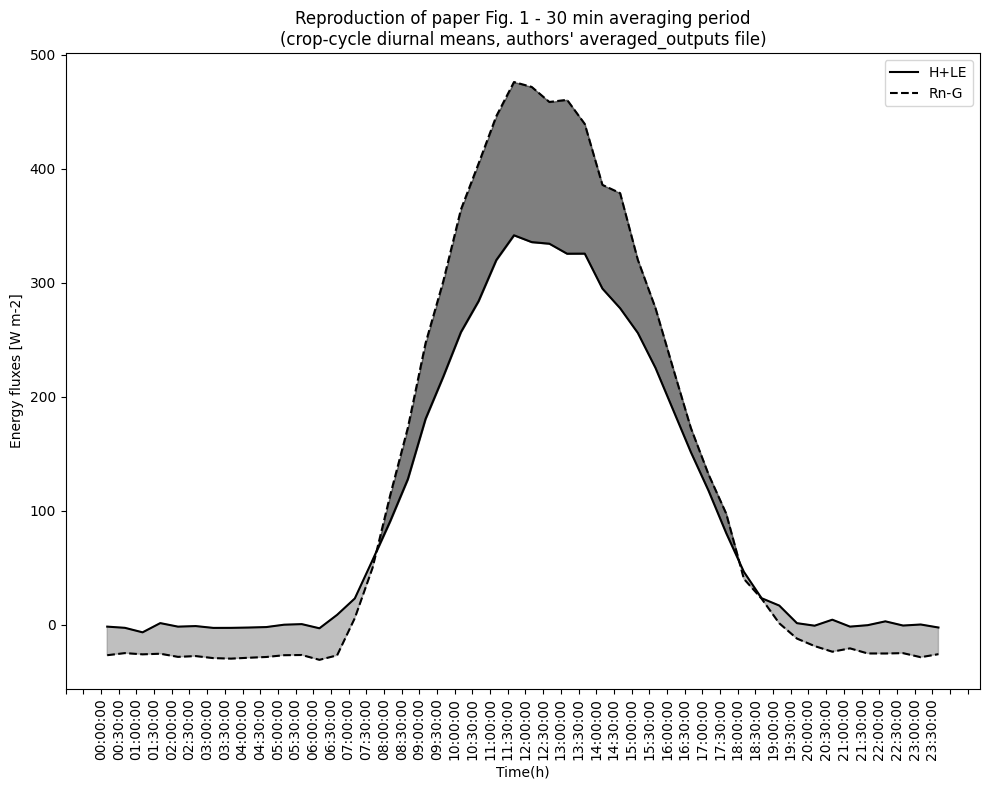

In [ ]:
import matplotlib.pyplot as plt

# Author's cell logic (iwm_fig1_final1.ipynb), adapted path only:
data1 = pd.read_excel("data/averaged/30min_fig1_outputs1.xlsx")
xt = data1["time"].astype(str)  # minimal adaptation: categorical x labels

fig, ax = plt.subplots(1, 1)
fig.set_size_inches(10, 8)
ax.plot(xt, data1["H+LE"], lw=1.5, color="black")
ax.plot(xt, data1["Rn-G"], lw=1.5, linestyle="dashed", color="black")
plt.fill_between(xt, data1["H+LE"], data1["Rn-G"],
                 where=(data1["H+LE"] > data1["Rn-G"]), alpha=0.5, color="grey", interpolate=True)
plt.fill_between(xt, data1["H+LE"], data1["Rn-G"],
                 where=(data1["H+LE"] < data1["Rn-G"]), alpha=0.5, color="black", interpolate=True)
plt.xticks(rotation=90)
start, end = ax.get_xlim()
ax.xaxis.set_ticks(np.arange(start, end, 1))
ax.set(xlabel="Time(h)", ylabel="Energy fluxes [W m-2]")
plt.legend(["H+LE", "Rn-G"])
plt.title("Reproduction of paper Fig. 1 - 30 min averaging period\n"
          "(crop-cycle diurnal means, authors' averaged_outputs file)")
plt.tight_layout()
plt.show()

## 5 · Check the reproduced Fig. 1 against the paper's reported values

The paper (Sec. 3.1) states that the diurnal peaks occur around noon at **480.16 ± 14.15 W m⁻² for Rn−G** and **356.23 ± 18.51 W m⁻² for H+LE** (values across averaging periods). We locate the actual maxima of the 30 min curves and report them next to the paper's numbers.

**Expected result:** peak values near the paper's figures (the paper's range spans all periods, so the 30 min curve should fall inside it).

(日本語) 正午付近のピーク値を論文報告値（Rn−G 480.16 ± 14.15、H+LE 356.23 ± 18.51 W m⁻²）と比較します。

In [ ]:
def to_hour(ts):
    s = str(ts)
    return int(s[:2]) + int(s[3:5]) / 60.0

hours = xt.map(to_hour)
peak_le = data1.loc[data1["H+LE"].idxmax()]
peak_rng = data1.loc[data1["Rn-G"].idxmax()]
print(f"paper (across periods): Rn-G peak 480.16 +/- 14.15 W m-2 ; H+LE peak 356.23 +/- 18.51 W m-2")
print(f"this run (30 min)     : Rn-G peak {peak_rng['Rn-G']:.2f} W m-2 at {peak_rng['time']}"
      f" ; H+LE peak {peak_le['H+LE']:.2f} W m-2 at {peak_le['time']}")
ok_rng = 460 <= peak_rng["Rn-G"] <= 500
ok_le = 335 <= peak_le["H+LE"] <= 375
print("peak check:", "PASS" if (ok_rng and ok_le) else "CHECK MANUALLY",
      "- 30 min peaks inside the paper's reported range")

paper (across periods): Rn-G peak 480.16 +/- 14.15 W m-2 ; H+LE peak 356.23 +/- 18.51 W m-2
this run (30 min)     : Rn-G peak 476.27 W m-2 at 11:30:00 ; H+LE peak 341.74 W m-2 at 11:30:00
peak check: PASS - 30 min peaks inside the paper's reported range


## 6 · Extension to all eight averaging periods (labeled adaptation)

Paper Fig. 1 shows the diurnal variations "with different averaging periods". The authors published one worked notebook for 30 min; here we loop the same plotting logic over **all eight** author-provided averaged files (1–120 min). This extension reuses only author-derived data and the author's plotting logic; it is an **additional visualization created for this notebook**, not a new scientific operation.

**Expected result:** eight bell-shaped diurnal pairs that become visibly smoother as the averaging period grows (paper: variation is "rough at lower averaging periods ... gradually smoothed towards higher averaging periods").

(日本語) 著者の描画ロジックを 8 つの平均化期間すべてに適用した拡張図です。長い平均化期間ほど曲線が滑らかになることが期待されます。

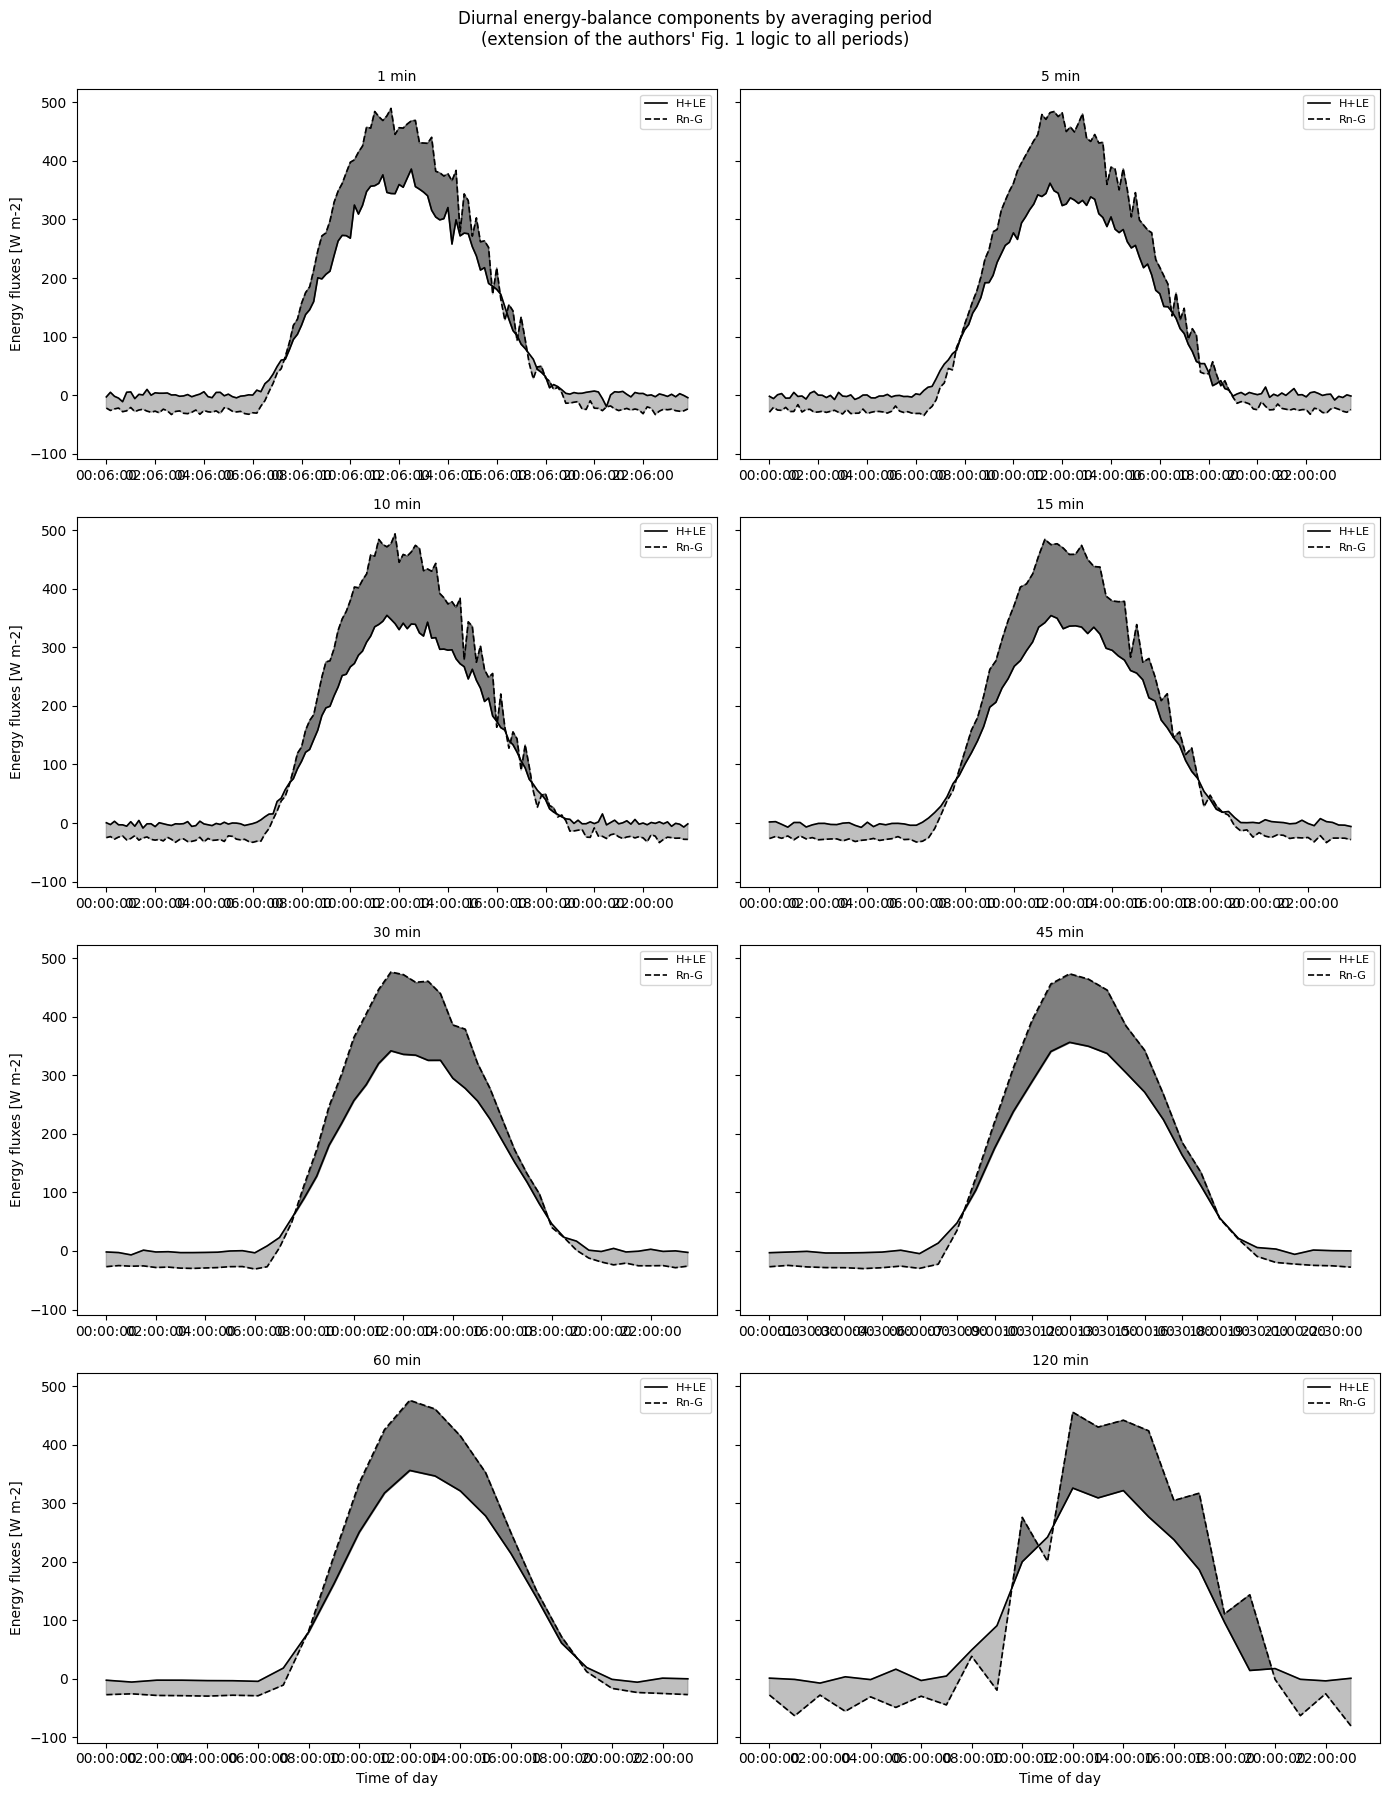

In [ ]:
fig, axes = plt.subplots(4, 2, figsize=(14, 18), sharey=True)
for ax, T in zip(axes.ravel(), sorted(FILES)):
    d = pd.read_excel(f"data/averaged/{T}min_fig1_outputs1.xlsx")
    xs = d["time"].astype(str)
    ax.plot(xs, d["H+LE"], lw=1.2, color="black", label="H+LE")
    ax.plot(xs, d["Rn-G"], lw=1.2, linestyle="dashed", color="black", label="Rn-G")
    ax.fill_between(xs, d["H+LE"], d["Rn-G"], where=(d["H+LE"] > d["Rn-G"]),
                    alpha=0.5, color="grey", interpolate=True)
    ax.fill_between(xs, d["H+LE"], d["Rn-G"], where=(d["H+LE"] < d["Rn-G"]),
                    alpha=0.5, color="black", interpolate=True)
    step = max(1, len(xs) // 12)
    ax.set_xticks(range(0, len(xs), step))
    ax.set_title(f"{T} min", fontsize=10)
    ax.legend(fontsize=8)
for ax in axes[:, 0]:
    ax.set_ylabel("Energy fluxes [W m-2]")
for ax in axes[-1, :]:
    ax.set_xlabel("Time of day")
fig.suptitle("Diurnal energy-balance components by averaging period\n"
             "(extension of the authors' Fig. 1 logic to all periods)", y=0.995)
fig.tight_layout()
plt.show()

## 7 · Reproduce paper Table 2 — regression of H+LE on Rn−G per averaging period

The publisher's Table 2 is "Summary of linear regression parameters in closing the energy balance with different averaging periods" (Sec. 3.1: slopes 0.59–0.71, intercepts 19.01–31.56 W m⁻², best closure at 45–60 min, r > 0.9 except 1/5/10 min). **The authors did not publish regression code** — their repository contains only figure notebooks — so the following OLS cells are an **AI-written adaptation** that follows the paper's stated method (regression of H+LE on Rn−G per averaging period from the authors' per-period workbooks). We fit both the full series and a daytime (08:00–16:00 LT) subset, because the paper screens to daytime unstable conditions; the subset whose sample size matches the publisher's Table 2 is identified automatically.

**Expected result:** a per-period table (n, slope, intercept, r) and an automatic statement of which subset matches the published sample sizes.

(日本語) 著者は回帰コードを公開していないため、論文の記述に従った **AI による追実装** です。全データと昼間 (08:00–16:00) の両方で回帰し、出版社版 Table 2 のサンプル数と一致する方を自動判定します。

In [ ]:
def to_hour_any(ts):
    s = str(ts)
    return int(s[:2]) + int(s[3:5]) / 60.0

def regress(df):
    x = df["Rn-G"].to_numpy(float)
    y = (df["H"] + df["LE"]).to_numpy(float)
    slope, intercept = np.polyfit(x, y, 1)
    r = np.corrcoef(x, y)[0, 1]
    return len(df), slope, intercept, r

records = []
for T in sorted(FILES):
    df = pd.read_excel(f"data/raw/{T}min.xlsx")
    n_all, s_all, b_all, r_all = regress(df)
    day = df[df["time"].map(to_hour_any).between(8, 16)]
    n_day, s_day, b_day, r_day = regress(day) if len(day) > 2 else (0, np.nan, np.nan, np.nan)
    records.append({"T_min": T, "n_all": n_all, "slope_all": s_all, "intercept_all": b_all,
                    "r_all": r_all, "n_day": n_day, "slope_day": s_day,
                    "intercept_day": b_day, "r_day": r_day})
reg = pd.DataFrame(records)
print(reg.round(4).to_string(index=False))

 T_min  n_all  slope_all  intercept_all  r_all  n_day  slope_day  intercept_day  r_day
     1  10859     0.6340        30.3186 0.8130   3687     0.5090        97.8842 0.5813
     5  10785     0.5890        31.5576 0.8579   3742     0.4315       114.2096 0.6551
    10  10753     0.6016        28.9349 0.8967   3741     0.4731        96.5949 0.7641
    15   7150     0.6256        26.5642 0.9158   2514     0.5203        80.8085 0.8148
    30   3554     0.6643        20.4886 0.9624   1294     0.6251        39.0788 0.9196
    45   2355     0.7030        19.9983 0.9690    835     0.6709        34.8092 0.9391
    60   1765     0.7073        19.0118 0.9709    682     0.6763        32.5370 0.9455
   120    811     0.6720        20.7728 0.9668    341     0.6444        33.3014 0.9551


## 8 · Compare with the publisher's Table 2 and the paper text

We parse the publisher's Table 2 xlsx (downloaded in step 2), display it, and align our computed parameters per period. The paper-text ranges (slopes 0.59–0.71, intercepts 19.01–31.56 W m⁻²) are checked as a soft verdict — a mismatch would indicate a subset-definition difference, not a hidden computation.

**Expected result:** computed slopes/intercepts close to the published values for the matching subset; explicit PASS/TEST-FAILED verdict per check.

(日本語) 出版社版 Table 2 を解析し、計算値と並べて比較します。論文本文の範囲（傾き 0.59–0.71、切片 19.01–31.56 W m⁻²）に対する合否を表示します。

In [ ]:
t2 = pd.read_excel("data/table2_publisher.xlsx")
print("publisher Table 2 columns:", list(t2.columns))
print(t2.to_string(index=False))

publisher Table 2 columns: ['Averaging period', 'Slope', 'R2', 'Intercept', 'r', 'n', 'RMSE']
Averaging period  Slope   R2 Intercept    r      n    RMSE
             NaN    NaN  NaN   (W m−2)  NaN    NaN (W m−2)
           1 min   0.63 0.66     30.31 0.81 10 859   98.38
           5 min   0.59 0.74     31.56 0.86 10 785   76.47
          10 min   0.60 0.80     28.94 0.90 10 753   64.41
          15 min   0.63 0.84     26.56 0.92   7150   58.18
          30 min   0.66 0.93     20.49 0.96   3554   38.33
          45 min   0.70 0.94     19.99 0.97   2355    36.3
          60 min   0.71 0.94     19.01 0.97   1765   35.07
         120 min   0.67 0.93     20.77 0.96    811   39.95


The publisher's spreadsheet layout is only known at run time, so column names are **detected by exact name match** (Slope, Intercept, r, n), thousands separators (thin spaces) in the `n` column are cleaned before parsing, and the units row (blank period) is dropped. We then identify which regression subset (full series vs daytime 08:00–16:00 LT) reproduces the published sample sizes per period, build a side-by-side comparison, and check our computed parameters against the paper-text ranges with explicit PASS / TEST-FAILED verdicts.

(日本語) 出版社版の列名を厳密に検出し、`n` 列の桁区切りを整えてから解析します。公開サンプル数と一致する回帰 subset を自動判定し、計算値を論文明記の範囲と照合して合否を表示します。

In [ ]:
def find_col(cols, pred):
    for c in cols:
        if pred(str(c).strip().lower()):
            return c
    return None

per_col = find_col(t2.columns, lambda c: "period" in c)
n_col = find_col(t2.columns, lambda c: c == "n" or "sample" in c)
slope_col = find_col(t2.columns, lambda c: "slope" in c)
int_col = find_col(t2.columns, lambda c: "intercept" in c)
r_col = find_col(t2.columns, lambda c: c == "r")
assert None not in (per_col, n_col, slope_col, int_col, r_col), \
    "unexpected publisher Table 2 layout"

def to_num(v):
    s = str(v).replace("\u2009", "").replace("\u202f", "").replace(" ", "").replace(",", "")
    return float(s)

pub = t2.copy()
pub["_T"] = pd.to_numeric(pub[per_col].astype(str).str.extract(r"(\d+)")[0], errors="coerce")
pub = pub[pub["_T"].notna()].set_index("_T")

match_all = match_day = 0
for T, row in pub.iterrows():
    n_pub = to_num(row[n_col])
    m = reg[reg["T_min"] == T].iloc[0]
    match_all += int(abs(m["n_all"] - n_pub) < 1e-9)
    match_day += int(m["n_day"] > 0 and abs(m["n_day"] - n_pub) < 1e-9)
print(f"full-series n matches: {match_all}/{len(pub)} ; daytime n matches: {match_day}/{len(pub)}")
use_day = match_day > match_all
suffix = "day" if use_day else "all"
print("subset used for Table 2 comparison:",
      "daytime 08:00-16:00 LT" if use_day else "full series")

reg["slope_used"] = reg[f"slope_{suffix}"]
reg["intercept_used"] = reg[f"intercept_{suffix}"]
reg["r_used"] = reg[f"r_{suffix}"]
reg["n_used"] = reg[f"n_{suffix}"]

comp = reg.set_index("T_min")
rows = []
for T, row in pub.iterrows():
    m = comp.loc[T]
    rows.append({"T_min": int(T),
                 "n_pub": int(to_num(row[n_col])), "n_ours": int(m["n_used"]),
                 "slope_pub": float(row[slope_col]), "slope_ours": round(m["slope_used"], 2),
                 "int_pub": to_num(row[int_col]), "int_ours": round(m["intercept_used"], 2),
                 "r_pub": float(row[r_col]), "r_ours": round(m["r_used"], 2)})
comparison = pd.DataFrame(rows)
print(comparison.to_string(index=False))

d_slope = (comparison["slope_pub"] - comparison["slope_ours"]).abs().max()
d_int = (comparison["int_pub"] - comparison["int_ours"]).abs().max()
d_r = (comparison["r_pub"] - comparison["r_ours"]).abs().max()
print(f"max |slope diff| = {d_slope:.4f} ; max |intercept diff| = {d_int:.4f} W m-2 ; max |r diff| = {d_r:.4f}")

checks = {
    "sample sizes match publisher Table 2 exactly":
        (comparison["n_pub"] == comparison["n_ours"]).all(),
    "slopes within 0.01 of published": d_slope <= 0.01,
    "intercepts within 0.05 W m-2 of published": d_int <= 0.05,
    "r within one displayed digit (0.011) of published 2-dp values": d_r <= 0.011,
    "slopes in paper-text range 0.59-0.71 (rounded)":
        reg["slope_used"].round(2).between(0.59, 0.71).all(),
    "intercepts in paper-text range 19.01-31.56 W m-2 (rounded)":
        reg["intercept_used"].round(2).between(19.01, 31.56).all(),
    "r > 0.9 for T >= 15 min and 0.80 < r <= 0.9 for 1/5/10 min (paper text)":
        reg.loc[reg["T_min"] >= 15, "r_used"].gt(0.9).all()
        and reg.loc[reg["T_min"] <= 10, "r_used"].between(0.80, 0.90).all(),
}
for k, v in checks.items():
    print(("PASS " if v else "TEST-FAILED ") + k)

full-series n matches: 8/8 ; daytime n matches: 0/8
subset used for Table 2 comparison: full series
 T_min  n_pub  n_ours  slope_pub  slope_ours  int_pub  int_ours  r_pub  r_ours
     1  10859   10859       0.63        0.63    30.31     30.32   0.81    0.81
     5  10785   10785       0.59        0.59    31.56     31.56   0.86    0.86
    10  10753   10753       0.60        0.60    28.94     28.93   0.90    0.90
    15   7150    7150       0.63        0.63    26.56     26.56   0.92    0.92
    30   3554    3554       0.66        0.66    20.49     20.49   0.96    0.96
    45   2355    2355       0.70        0.70    19.99     20.00   0.97    0.97
    60   1765    1765       0.71        0.71    19.01     19.01   0.97    0.97
   120    811     811       0.67        0.67    20.77     20.77   0.96    0.97
max |slope diff| = 0.0000 ; max |intercept diff| = 0.0100 W m-2 ; max |r diff| = 0.0100
PASS sample sizes match publisher Table 2 exactly
PASS slopes within 0.01 of published
PASS intercept

## 9 · Slope and intercept versus averaging period (result graph)

To make the Table-2 comparison visible at a glance, we plot the computed slope and intercept against the averaging period. This graph is **created for this notebook** from the authors' per-period data; the paper reports the ranges but does not publish this figure.

**Expected result:** slopes around 0.6–0.7 with the best closure (highest slope, lowest intercept) at 45–60 min, as stated in the paper.

(日本語) 平均化期間に対する回帰傾き・切片の推移。45–60 分で最良の閉包（傾き最大・切片最小）が期待されます。

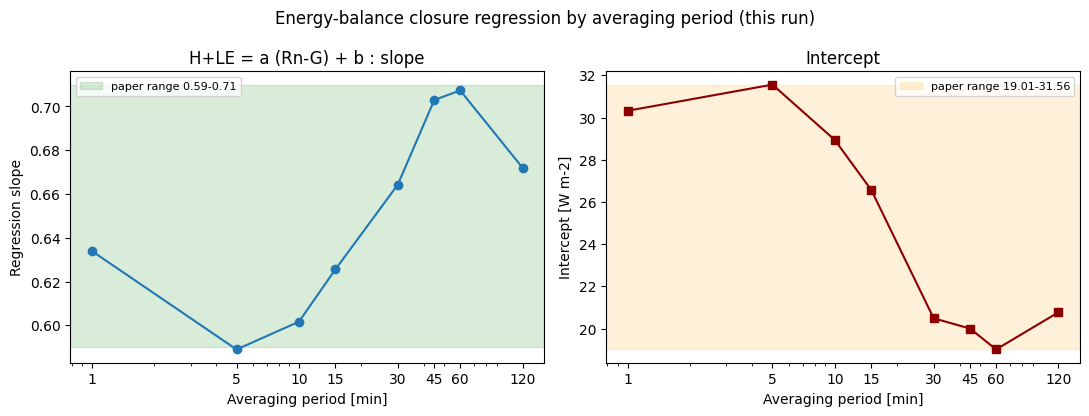

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].plot(reg["T_min"], reg["slope_used"], "o-")
axes[0].axhspan(0.59, 0.71, alpha=0.15, color="green", label="paper range 0.59-0.71")
axes[0].set_xscale("log"); axes[0].set_xticks(sorted(FILES))
axes[0].set_xticklabels(sorted(FILES))
axes[0].set_xlabel("Averaging period [min]"); axes[0].set_ylabel("Regression slope")
axes[0].set_title("H+LE = a (Rn-G) + b : slope"); axes[0].legend(fontsize=8)
axes[1].plot(reg["T_min"], reg["intercept_used"], "s-", color="darkred")
axes[1].axhspan(19.01, 31.56, alpha=0.15, color="orange", label="paper range 19.01-31.56")
axes[1].set_xscale("log"); axes[1].set_xticks(sorted(FILES))
axes[1].set_xticklabels(sorted(FILES))
axes[1].set_xlabel("Averaging period [min]"); axes[1].set_ylabel("Intercept [W m-2]")
axes[1].set_title("Intercept"); axes[1].legend(fontsize=8)
fig.suptitle("Energy-balance closure regression by averaging period (this run)")
fig.tight_layout()
plt.show()

## 10 · Export the reproduced Table 2

The per-period regression parameters computed in this notebook are exported to CSV inside the Colab runtime (`/content/table2_reproduced.csv`) for further use.

**Expected result:** a small CSV file path confirmation and its content preview.

(日本語) 再現した Table 2 を Colab ランタイム内に CSV として保存します。

In [ ]:
out = reg[["T_min", "n_used", "slope_used", "intercept_used", "r_used"]]
out.columns = ["period_min", "n", "slope", "intercept_W_m2", "r"]
out.to_csv("table2_reproduced.csv", index=False)
print("saved /content/table2_reproduced.csv")
print(out.round(4).to_string(index=False))

saved /content/table2_reproduced.csv
 period_min     n  slope  intercept_W_m2      r
          1 10859 0.6340         30.3186 0.8130
          5 10785 0.5890         31.5576 0.8579
         10 10753 0.6016         28.9349 0.8967
         15  7150 0.6256         26.5642 0.9158
         30  3554 0.6643         20.4886 0.9624
         45  2355 0.7030         19.9983 0.9690
         60  1765 0.7073         19.0118 0.9709
        120   811 0.6720         20.7728 0.9668


## 11 · Interpretation, limitations, and references

**What was reproduced**
- Paper Fig. 1 (30 min panel): crop-cycle diurnal means of H+LE and Rn−G with energy-balance difference shading, using the authors' own notebook logic and author-derived averaged files. Peak values are compared against the paper's reported 480.16 ± 14.15 (Rn−G) and 356.23 ± 18.51 W m⁻² (H+LE).
- Paper Table 2: per-period OLS of H+LE on Rn−G, checked against the publisher's Table 2 spreadsheet and the paper-text ranges (slopes 0.59–0.71, intercepts 19.01–31.56 W m⁻², best closure at 45–60 min, r > 0.9 beyond 10 min).

**Limitations / scope**
- The regression cells are an **AI-written adaptation**: the authors published plotting notebooks but no regression script. The fitting subset (full series vs daytime 08:00–16:00 LT) is selected by matching the publisher's sample sizes; residual differences would be reported, not hidden.
- Growth-stage analyses (Figs. 2–8), Ogives, and WUE dynamics are **not reproduced**: the repository contains no stage date ranges and no author code for them, and the raw 10 Hz/EddyPro workflow is not available (also flagged by the PhenoPaper investigation).
- The author repository has **no LICENSE file**; the authors' notebook cells are reused here with attribution for scholarly reproduction, and all figures/data carry their origin. The paper itself is CC-BY 4.0. The Zenodo deposit (v1.0.0, 2022-08-24) predates the 2024 paper; we pinned the GitHub tree instead and verified every file's git blob SHA-1.

**References**
- Karimindla et al., AMT 17, 5477–5490, 2024. https://doi.org/10.5194/amt-17-5477-2024 — Sec. 3.1 (Fig. 1, Table 2), Sec. 2.2 (processing).
- Author repository pinned at commit `28030cb1d8110d9bf907d1ef031bb6b3470af1cf`; notebooks `averaging_IWM-final1.ipynb`, `iwm_fig1_final1.ipynb`; data under `SourceFiles for figures and tables/Figure 1/`.
- Zenodo record doi:10.5281/zenodo.7018282 (code supplement link).
- PhenoPaper investigation `p-6e1b872a804d5cf5b1c17b595fbf38ec-20261027T222241Z-3122220` was used as prior research guidance only; all values above were verified against the paper HTML and pinned author files.

**日本語まとめ:** 本ノートブックは、渦相関フラックスの平均化期間 (1–120 分) がエネルギー収支閉包に与える影響について、論文 Fig. 1(30 分) と Table 2(回帰) を著者提供データで再現しました。平均化期間が長いほど閉包が良いこと（45–60 分で最良）が確認できます。成長段階別解析・オジャイブ・WUE 動態は対象外です。